# Calibración y rectificación estéreo

Este notebook **calibra desde las imágenes de `data/calibration`**. Detecta el
checkerboard, estima los parámetros de ambas cámaras y su transformación relativa,
valida el resultado y guarda los archivos que consume el notebook 02.
Los `.pkl` anteriores no intervienen en la estimación.

## Checkerboard usado

| Parámetro | Valor |
|---|---|
| Esquinas internas (columnas × filas) | 9 × 6 (54 puntos) |
| Cantidad de cuadrados (columnas × filas) | 10 × 7 |
| Lado configurado de cada cuadrado | 28 mm |
| Tamaño del patrón, sin márgenes | 280 × 196 mm |

El lado físico del cuadrado fija la escala de `T` y de las nubes obtenidas con `Q`.
La configuración usa 28 mm; confirmar esta medida en el tablero impreso antes de
reportar dimensiones del objeto.

In [1]:
import sys
from pathlib import Path

# Funciona con el kernel iniciado desde la raíz o desde notebooks/.
ROOT_DIR = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "src").is_dir() and (directory / "data").is_dir()
)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

## 1. Configuración y pares de calibración

In [2]:
from src.utils.prints import print_calibration_results, print_calibration_diagnostics
from src.utils.plotting import show_calibration_errors, show_rectification_example
from src.calibration_rectification import (
    load_calibration_data,
    save_calibration_results,
    calibrate_and_evaluate,
)

CALIBRATION_IMAGES_DIR = ROOT_DIR / "data/calibration"
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"
REPORT_IMAGES_DIR = ROOT_DIR / "report/report_images"
COLS, ROWS = 9, 6
SQUARE_SIZE_MM = 28.0
RECTIFICATION_ALPHA = 0.0
TAU_PX = 3
MAX_CALIB_ITER = 100

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [3]:
calibration_data = load_calibration_data(
    CALIBRATION_IMAGES_DIR, square_size=SQUARE_SIZE_MM, rows=ROWS, cols=COLS
)
image_size = calibration_data["image_size"]
print(f"Tamaño por cámara: {image_size} px (ancho, alto)")
print(
    f"Pares con tablero detectado: {len(calibration_data['used_pair_ids'])} / {len(calibration_data['pair_ids'])}"
)
print(
    f"Índices descartados sin detección en ambas cámaras: {calibration_data['rejected_pair_ids']}"
)

Tamaño por cámara: (1920, 1080) px (ancho, alto)
Pares con tablero detectado: 49 / 63
Índices descartados sin detección en ambas cámaras: [5, 6, 7, 9, 29, 31, 32, 48, 49, 51, 56, 57, 58, 61]


## 2. Calibración monocular y estéreo; rectificación y evaluación

In [4]:
calib_results = calibrate_and_evaluate(
    calibration_data,
    image_size,
    alpha=RECTIFICATION_ALPHA,
    tau=TAU_PX,
    max_iter=MAX_CALIB_ITER,
)

calib = calib_results["calib"]
calibration_rms = calib_results["calibration_rms"]

print_calibration_results(calib, calibration_rms)

602.891,0,970.403
0,603.572,533.896
0,0,1


595.948,0,955.307
0,596.32,523.919
0,0,1


0.000959944,-0.0163207,-0.00300238,-0.00139297,-0.000333273


0.00968686,-0.0306355,-0.0027655,-0.000453122,0.00544747


0.999987,0.000130987,0.00500847
-0.000121235,0.999998,-0.00194736
-0.00500871,0.00194673,0.999986


-60.1229
0.156318
-2.15031


-0.00104365,2.15061,0.152129
-2.45142,0.116761,60.1113
-0.149027,-60.1229,0.116298


-1.90639e-08,3.92402e-05,-0.0192563
-4.47514e-05,2.12911e-06,0.703872
0.021842,-0.69236,1


RMS calibración monocular izquierda: 0.869 px
RMS calibración monocular derecha: 0.609 px
RMS calibración estéreo (OpenCV): 0.860 px
Baseline |t| = 60.16 mm


Cantidad de pares guardados: 13
RMS de validación estéreo con pose izquierda: 0.988 px
Desalineación vertical rectificada RMS: 0.654 px
Focal rectificada: 659.28 px | alpha = 0.0

Cinco pares con mayor error de reproyección derecha:
  Par | Izquierda (px) | Derecha (px) | Vertical (px)
   42 |          0.584 |        2.016 |         1.386
   52 |          2.298 |        1.365 |         1.112
    4 |          0.787 |        1.344 |         0.343
   24 |          0.666 |        1.105 |         0.328
    3 |          0.821 |        0.987 |         0.332


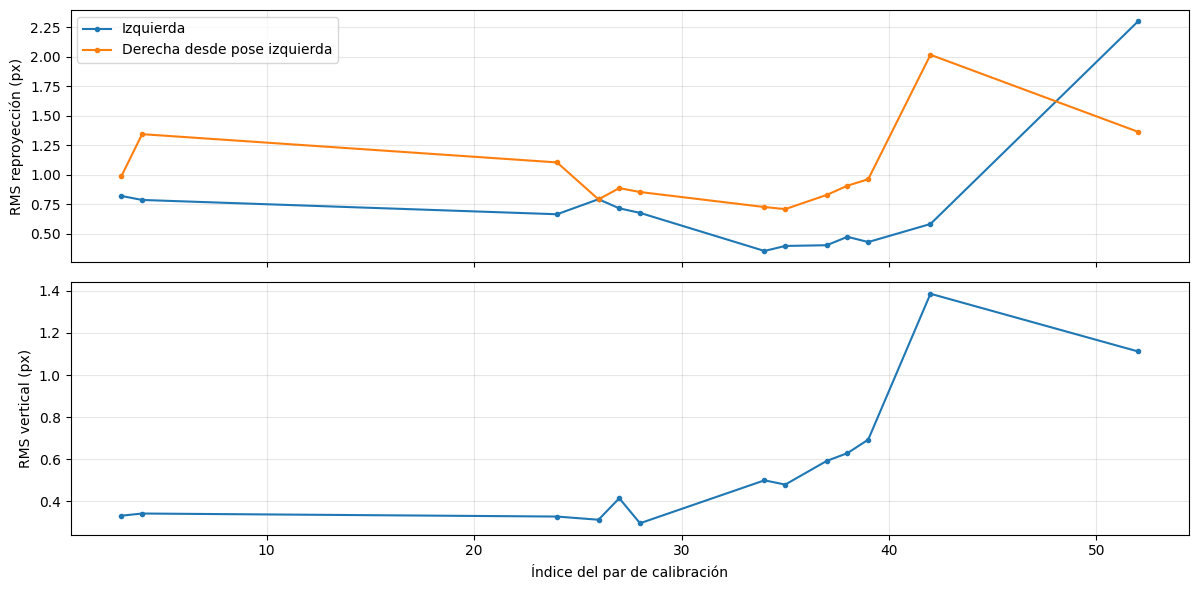

In [5]:
maps = calib_results["maps"]
diagnostics = calib_results["diagnostics"]

print_calibration_diagnostics(diagnostics, maps["P1"][0, 0], RECTIFICATION_ALPHA)
show_calibration_errors(
    diagnostics, save_path=REPORT_IMAGES_DIR / "errores_calibracion.png"
)

## 3. Ejemplo original y rectificado

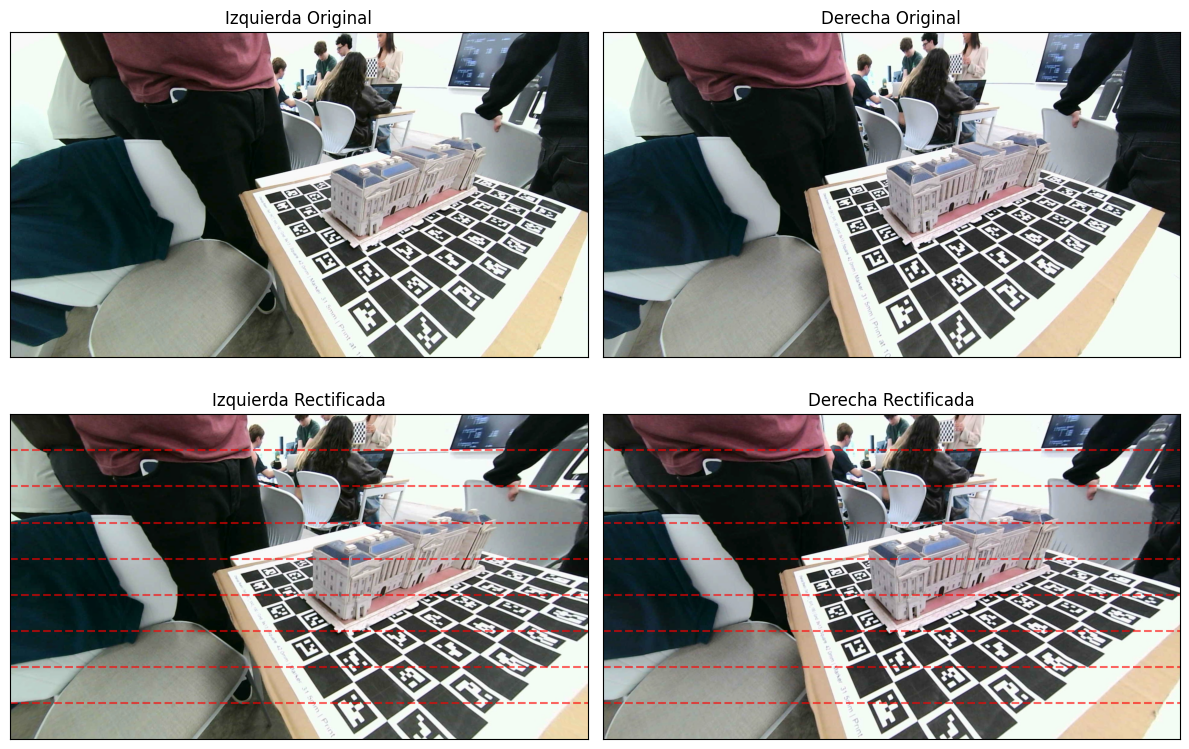

In [6]:
show_rectification_example(
    dataset_name="palacio",
    index=diagnostics["rows"][0]["pair_id"],
    maps=maps,
    image_size=image_size,
    save_path=REPORT_IMAGES_DIR / "rectificacion_palacio.png",
)

## 4. Guardar resultados

In [7]:
metadata = save_calibration_results(
    CALIBRATION_DIR,
    calib,
    maps,
    calibration_rms,
    calib_results["filtered_data"],
    diagnostics,
    root_dir=ROOT_DIR,
    rows=ROWS,
    cols=COLS,
    square_size_mm=SQUARE_SIZE_MM,
    rectification_alpha=RECTIFICATION_ALPHA,
)
print(
    f"Calibración, mapas y diagnóstico guardados en {CALIBRATION_DIR.relative_to(ROOT_DIR)}"
)

Calibración, mapas y diagnóstico guardados en data/calibration_results
